# BIOT 6900 · Module 9 — Notebook 3 (GRADED)
## Clinical NLP on your own disease: build it, then catch the leakage
**Week 9 · Part III · this is the graded assignment**

> **⚠️ SYNTHETIC.** You design a synthetic patient population for a disease of your choice, run the full pipeline on it, and then do the hard part: look at what the model learned and separate genuine early signal from leakage.

You configure your disease's clinical picture (which findings are genuine early signals, which are interventions done to deteriorating patients). The notebook builds a cohort and notes from your choices, extracts features, trains a model, and reports permutation importance. **It also injects two clinical features you did not configure** — you must diagnose each as signal or leakage from the output.

**What is graded (course 60 / 40):** 60% execution (your config is clinically sensible, the notebook runs, the pipeline is correct) and **40% interpretation** (Part D: correctly sorting signal from leakage and defending it). See the assignment sheet for the rubric.

**How to run:** `Kernel → Restart & Run All`. It uses only `pandas` + `scikit-learn`.

## The engine (provided, do not edit)
Run this cell and move on. It defines the assertion engine, the cohort/notes generator, and the model helpers.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure your disease  (TODO)
Replace the EXAMPLE config with **your own disease**. You need:
- 2–3 **signals**: genuine, *early* findings that are **causes** of deterioration (present before things go wrong).
- 2–3 **consequences**: interventions or actions taken *because* a patient is deteriorating. These are your planted leakage.
- For each, give a few **synonyms / abbreviations** (the notes will use them at random, so normalization matters).

Choosing these well is a clinical-reasoning task, and it is graded. A cause belongs in `signals`; a treatment or end-of-life decision belongs in `consequences`.

In [2]:
# ======== EDIT THIS: replace the example with YOUR disease ========
# Disease carried over from my Modules 2-7: Alzheimer's disease (MONDO:0004975).
# Framing: hospitalized AD patients, outcome = in-hospital death.
# Sources (short form):
#   HPO phenotype.hpoa [Gargano 2024], used in Module 7 for the AD phenotypes
#       doi:10.1093/nar/gkad1005
#   GWAS Catalog MONDO_0004975 [Sollis 2023], Module 2 ad_gwas.tsv (APOE rs429358 / rs7412)
#       doi:10.1093/nar/gkac1010
#   PGS000334 [Zhang 2020; Lambert 2021], 1000 Genomes [1000G 2015], Module 6 PRS (APOE e4)
#       Zhang 2020: doi:10.1038/s41467-020-18534-1 | Lambert 2021: doi:10.1038/s41588-021-00783-5
#       1000G 2015: doi:10.1038/nature15393
#   Open Targets [Buniello 2025]; ChEMBL [Zdrazil 2024], Module 7 drugs (lecanemab, donanemab)
#       Buniello 2025: doi:10.1093/nar/gkae1128 | Zdrazil 2024: doi:10.1093/nar/gkad1004
#   Lecanemab appropriate-use recs [Cummings 2023] (stop or hold therapy on ARIA or progression)
#       doi:10.14283/jpad.2023.30
#   Advanced-dementia clinical course [Mitchell 2009] (eating problems, feeding tubes, hospice)
#       doi:10.1056/NEJMoa0902234
#   Seizures in AD [Vossel 2017]
#       doi:10.1016/S1474-4422(17)30044-3
CONFIG = {
    "disease": "Alzheimer's disease (hospitalized patients, in-hospital mortality)",
    "signals": {                                              # genuine EARLY signals (causes, present before decline)
        # HPO AD phenotype in my Module 7 graph [Gargano 2024]; seizures speed decline in AD [Vossel 2017]
        "seizure":         ["seizure", "seizures", "convulsion", "epileptic activity"],
        # HPO AD phenotype in my Module 7 graph [Gargano 2024]; leads to falls and immobility
        "gait_disturbance": ["gait disturbance", "unsteady gait", "gait instability", "frequent falls"],
        # Top AD GWAS hit in Module 2 (APOE p = 1e-300) [Sollis 2023]; ε4 drives the Module 6 PRS [Zhang 2020].
        # A germline genotype exists from birth, so it cannot be caused by the outcome.
        "apoe4_carrier":   ["apoe e4", "apoe4", "apoe e4/e4", "e4 carrier"],
    },
    "consequences": {                                         # interventions on deteriorating patients (LEAKAGE)
        # Module 7 drugs (Open Targets / ChEMBL); stopped because of ARIA or progression [Cummings 2023]
        "anti_amyloid_stopped": ["lecanemab discontinued", "donanemab discontinued", "anti-amyloid therapy stopped"],
        # Placed when advanced dementia stops eating safely [Mitchell 2009]
        "feeding_tube":         ["feeding tube", "peg tube", "gastrostomy tube"],
        # End-of-life decision [Mitchell 2009]
        "comfort_care":         ["comfort care", "cmo", "hospice"],
    },
}

SEED = 1386377
# =================================================================

struct, NOTES = build_world(CONFIG, seed=SEED, N=400)
print("#"*70)
print(f"# SYNTHETIC cohort for: {CONFIG['disease']}")
print(f"# 400 patients, 3 notes each. Mortality prevalence = {struct.died.mean():.2f}")
print("#"*70)
print("Example patient notes:")
for tag, t in zip(["admit ", "day 2 ", "final "], NOTES[0]):
    print(f"  [{tag}] {t}")

######################################################################
# SYNTHETIC cohort for: Alzheimer's disease (hospitalized patients, in-hospital mortality)
# 400 patients, 3 notes each. Mortality prevalence = 0.24
######################################################################
Example patient notes:
  [admit ] 51M admitted to the ICU. Lactate 2.1, creatinine 0.7. Clinical note: convulsion present.
  [day 2 ] Progress note, hospital day 2.
  [final ] Discharge / final note. Stable for discharge.


## Part B — Extract features  (TODO)
Assemble every concept to extract: your signals, your consequences, and the two injected wildcards. Then run the extractor across all 400 patients.

In [3]:
# the two injected features you did NOT configure are added here for you:
ALL_CONCEPTS = {**CONFIG["signals"], **CONFIG["consequences"], **WILDCARDS}

feat = pd.DataFrame({"subject_id": struct.subject_id})
for name, syns in ALL_CONCEPTS.items():
    feat[name] = [concept_present(syns, NOTES[i]) for i in range(400)]

print("Patients with each concept asserted PRESENT:")
print(feat.drop(columns="subject_id").sum().to_string())

Patients with each concept asserted PRESENT:
seizure                 123
gait_disturbance        110
apoe4_carrier            85
anti_amyloid_stopped     75
feeding_tube             78
comfort_care             85
lactate_not_clearing     71
renal_replacement        71


Sanity check: compare naive keyword counting to assertion-aware counting for one of your signals.

In [4]:
one_signal = list(CONFIG["signals"])[0]
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
aware = int(feat[one_signal].sum())
print(f"{one_signal}:  naive keyword count = {naive}   assertion-aware = {aware}")

seizure:  naive keyword count = 184   assertion-aware = 123


## Part C — Model and importance  (TODO)
Build the feature matrix, then **declare which of YOUR concepts you planted as leakage**. Do not include the wildcards yet — you have to find those in Part D.

In [5]:
df = struct.merge(feat, on="subject_id")
df["sex_F"] = (df.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
concept_cols = list(ALL_CONCEPTS)
all_cols = struct_cols + concept_cols

# TODO: list the concepts YOU configured as consequences (your planted leakage)
declared_leak = list(CONFIG["consequences"])     # EDIT if you want; by default your consequences

m, sd   = cv_auroc(df, all_cols)
mh, sdh = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"CV AUROC   all features = {m:.3f} ± {sd:.3f}")
print(f"CV AUROC   your declared leakage removed = {mh:.3f} ± {sdh:.3f}")

CV AUROC   all features = 0.912 ± 0.031
CV AUROC   your declared leakage removed = 0.780 ± 0.081


comfort_care            0.090
renal_replacement       0.066
feeding_tube            0.045
anti_amyloid_stopped    0.020
age                     0.015
lactate_not_clearing    0.013
lactate                 0.002
creatinine              0.001
apoe4_carrier          -0.001
gait_disturbance       -0.003
sex_F                  -0.004
seizure                -0.006


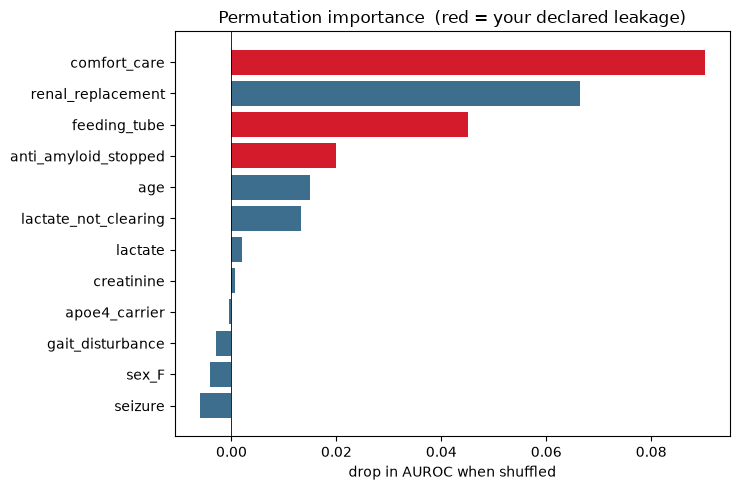

In [6]:
imp = perm_importance(df, all_cols)
print(imp.round(3).to_string())

order = imp.sort_values()
leakset = set(declared_leak)
colors = ["#D41B2C" if c in leakset else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7.5, 5))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = your declared leakage)")
plt.xlabel("drop in AUROC when shuffled"); plt.tight_layout(); plt.show()

## Part D — Catch the leakage and interpret  (GRADED, the 40%)
Now the real work. Answer each prompt in the markdown cell that follows it. Use the permutation importance and the AUROC numbers as evidence, and clinical reasoning (cause vs consequence) as the argument.

### D1. Read the importance plot
List the features at the **top** of the permutation-importance ranking. For each, say whether it is genuine early **signal** or **leakage**, and give a one-sentence clinical reason (is it a cause the patient had, or a consequence of them deteriorating?).

> 1. comfort_care: Leakage. Hospice care is a type of care given to make patients who are almost certainly going to pass away be more comfortable in the process, meaning it relies on the physicians observation that the patient's condition has deteriorated.
> 2. renal_replacement: Leakage. Renal replacement is a process of clearing the blood of toxins in case of kidney failure, which has nothing to do with AD at all, and even in its own field relies on the kidneys having already failed.
> 3. feeding_tube: Leakage. Feeding tubes are used when someone can no longer feed themselves, so this depends on late-stage outcomes.
> 4. anti_amyloid_stopped: Leakage. Stopping anti amyloid treatment occurs because ARIA events worsen or occur too many times, which is a direct indication of deteriorating health, making this leakage.
> 5. age: Real signal. Age does not depend on any other factors, so it can be used as a real signal in the model.
> 6. lactate_not_clearing: Real signal. Lactate not clearing is something that is noted during admission, so it does not rely on later condition.

### D2. Hunt the hidden leak
Your 'declared leakage removed' AUROC is probably still high. That is a clue you missed a leak. Two features were injected that you did not configure: **`lactate_not_clearing`** and **`renal_replacement`**. From the importance plot and clinical reasoning, classify each as signal or leakage, and justify. Then add any you judge to be leakage to the set below and re-run.

> Renal replacement is certainly leakage, since as I stated before, it is done to clear toxins from the bloodstream and therefore is caused by deteriorating health. It is also ranked as more important than two of the known leaks, which is consistent with leakage.  
>  
> Lactate not clearing is not leakage, given that it is something that is noted as the patient is admitted into the hospital. It gives a legitimate metric of the patient's general state, making it a good candidate for signalling. It is one of the strongest indicators besides leakage, which is consistent with it being a signal.

In [7]:
# TODO: your FINAL leak set = your declared leakage + any wildcard you caught
final_leak = declared_leak + ["renal_replacement"]     # EDIT based on your D2 decision

m_all, _    = cv_auroc(df, all_cols)
m_honest, _ = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC with everything     = {m_all:.3f}")
print(f"AUROC, all leakage removed = {m_honest:.3f}")

# does a wildcard you kept as signal actually matter once leakage is gone?
honest_imp = perm_importance(df, [c for c in all_cols if c not in final_leak])
print("\nHonest-model importance (top 6):")
print(honest_imp.head(6).round(3).to_string())

AUROC with everything     = 0.912
AUROC, all leakage removed = 0.680

Honest-model importance (top 6):
age                     0.139
lactate                 0.081
lactate_not_clearing    0.046
apoe4_carrier           0.024
seizure                 0.011
gait_disturbance        0.009


### D3. Quantify the damage
Report the AUROC with everything, with your declared leakage removed, and with all leakage removed (including any wildcard you caught). What does the size of each drop tell you about how much of the model's apparent skill was leakage?

> The AUROC with everything is 0.912, with declared leakage removed is 0.780, and with all leakage removed is 0.680.  
>  
> The largest drop was with the declared leakage, which caused a drop of 0.132. This indicates heavy reliance on the declared leakage in the skill of the model. The model AUROC dropped by another 0.1 with the renal replacement leakage removed, indicating yet another strong reliance on leakage in the model. The model looked strong with the AUROC of 0.912, but without leakage it is only 0.680, which is only modestly better than a 50/50 chance (AUROC of 0.5).

### D4. Reality check
Pick your two strongest genuine signals. Would they actually be **documented early enough** to act on in a real chart? Name one way this synthetic cohort is unlike real clinical data (think about the lecture's documentation-bias and small-cohort points).

> The two strongest signals were age and lactate. Age would be documented immediately in a real chart, meaning it certainly would be early enough to act in a real situation.  
>  
> Lactate would be recorded early enough in the case of sepsis, but not in the case of an Alzheimer's Disease patient. This synthetic dataset was built for sepsis, causing an internal bias toward it as a signal. Lactate levels wouldn't necessarily be measured for an AD patient, so it probably wouldn't be measured quickly enough to act on, while in the synthetic data, every patient has their lactate measured.

## What to submit
- This notebook, run top to bottom (`Kernel → Restart & Run All`), committed to your biot6900 repo.
- Your written answers to D1–D4 in the markdown cells above.
- A short README noting your disease and anything that did not work.

Then post your repo link on Canvas. Grading follows the assignment sheet (course 60 / 40).